[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/10_neural-networks.ipynb)

*Machine Learning from Scratch · Notebook 10 of 10*

# Neural Networks

From one neuron to a trained network: logic gates, why XOR needs a hidden layer, activations, forward passes, loss functions, backpropagation, SGD, momentum and Adam, initialisation, dropout and mini-batches.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A neural network is many simple decisions stacked together, each layer building on the last.

**What interviewers really test here:** Backpropagation, activations, why non-linearity matters, and optimisers.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. One neuron, then many *(Basics)*
- [ ] 2. A forward pass by hand *(Basics)*
- [ ] 3. Activations and the forward pass *(Core)*
- [ ] 4. Backpropagation *(Core)*
- [ ] 5. Backpropagation with real numbers *(Core)*
- [ ] 6. How hidden neurons build curves *(Core)*
- [ ] 7. Momentum and Adam by hand *(Core)*
- [ ] 8. Optimisers and practical training *(Advanced)*
- [ ] 9. A real network in scikit-learn *(Advanced)*
- [ ] 10. Vanishing gradients *(Advanced)*
- [ ] 11. Debugging a network that won't learn *(Advanced)*
- [ ] 12. A whole network from scratch *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Architecture

A **multi-layer perceptron** (MLP) is a composition of layers: h⁽ˡ⁾ = g(W⁽ˡ⁾h⁽ˡ⁻¹⁾ + b⁽ˡ⁾), with h⁽⁰⁾ = x. A layer from a inputs to b outputs has a·b + b parameters. **Depth** is the number of layers, **width** the neurons per layer.



| Task | Output layer | Loss |
| --- | --- | --- |
| Regression | linear | (half) mean squared error |
| Binary classification | 1 sigmoid | binary cross-entropy |
| Multi-class | k softmax | categorical cross-entropy |
| Multi-label | k sigmoids | binary cross-entropy per label |

### Backpropagation

For a network x → h → ŷ → L, the chain rule gives ∂L/∂W = (∂L/∂ŷ)(∂ŷ/∂h)(∂h/∂W). Backprop evaluates this from the output backwards, reusing intermediate results, so all gradients cost about one extra pass. It is **reverse-mode automatic differentiation**, which PyTorch and JAX perform for you.




- **Vanishing gradients**: products of small slopes shrink towards 0 (sigmoid, tanh, very deep nets).
- **Exploding gradients**: products of large values grow; use gradient clipping.
- **Dead ReLUs**: neurons stuck at 0 output with zero gradient; try a lower learning rate or Leaky ReLU.

### Optimisers

| Optimiser | Update |
| --- | --- |
| SGD | w ← w − η·g |
| Momentum | v ← μv − η·g; w ← w + v |
| RMSProp | divide by a running average of g² |
| Adam | m ← β₁m + (1 − β₁)g; v ← β₂v + (1 − β₂)g²; w ← w − η·m̂/(√v̂ + ε), with bias correction |
| AdamW | Adam with weight decay kept separate from the gradient |



The learning rate is the most important setting. Schedules (step, cosine, warm-up) reduce it during training. An **epoch** is one pass through the data; a **batch** is the group used for one step.

### Initialisation and regularisation

| Technique | What it does |
| --- | --- |
| Random initialisation | breaks symmetry; all-zero weights make every neuron identical |
| Glorot / Xavier | scales the range by fan-in + fan-out; suits tanh and sigmoid |
| He | scales by fan-in; suits ReLU |
| L2 / weight decay | penalises large weights |
| Dropout | randomly zeroes activations while training, scaled by 1/keep |
| Batch / layer normalisation | stabilises each layer's inputs |
| Early stopping | stops when validation loss stops improving |
| Data augmentation | more varied training examples |

### Beyond the MLP

| Architecture | Key idea | Used for |
| --- | --- | --- |
| CNN | small filters shared across an image | images, some audio |
| RNN / LSTM | state carried along a sequence | time series, older language models |
| Transformer | attention: every token weighs every other token | language, LLMs, much more |
| Autoencoder | compress, then reconstruct | representations, anomaly detection |



For tables, gradient-boosted trees usually beat MLPs with far less tuning.

---
# Part 2: Lessons, step by step

## Lesson 1: One neuron, then many

*Level: Basics*

A **neuron** is a weighted sum passed through a function: **output = activation(w·x + b)**. You've met it already: with a sigmoid it's logistic regression, and with a step it's the perceptron.



One neuron can only draw one straight line. It can do AND and OR, but not **XOR** (true when the inputs differ), because no single line separates those points.



The fix is to **stack neurons**. A hidden layer computes new features, such as OR and NAND, and the next layer combines them: XOR = AND(OR, NAND). A network is layers of neurons, each feeding the next.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

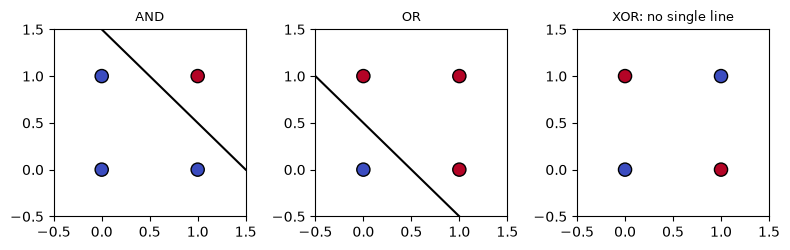

In [2]:
GATE = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)


def gates_picture():
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.6))
    tables = [("AND", [0, 0, 0, 1], (1, 1, -1.5)), ("OR", [0, 1, 1, 1], (1, 1, -0.5)), ("XOR: no single line", [0, 1, 1, 0], None)]
    xs = np.linspace(-0.5, 1.5, 10)
    for ax, (name, y, line) in zip(axes, tables):
        ax.scatter(GATE[:, 0], GATE[:, 1], c=y, cmap="coolwarm", s=90, edgecolor="black")
        if line:
            ax.plot(xs, -(line[0] * xs + line[2]) / line[1], color="black")
        ax.set_xlim(-0.5, 1.5)
        ax.set_ylim(-0.5, 1.5)
        ax.set_title(name, fontsize=9)
    fig.tight_layout()


gates_picture()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 2: A forward pass by hand

*Level: Basics*

A network with 2 inputs, 2 hidden ReLU neurons and 1 output. Input x = (2, 1).



#### Hidden layer



| Neuron | Weights | Bias | z = w·x + b | ReLU(z) |
| --- | --- | --- | --- | --- |
| h₁ | 0.5, −1 | 0 | 0.5·2 − 1·1 + 0 = 0 | 0 |
| h₂ | 1, 1 | −1 | 1·2 + 1·1 − 1 = 2 | 2 |



#### Output



Weights 1 and −0.5, bias 0.5: ŷ = 1·0 + (−0.5)·2 + 0.5 = **−0.5**.



#### In matrix form



```python
h = np.maximum(0, W1 @ x + b1)
y = W2 @ h + b2
```



**Parameters here:** (2 × 2 + 2) + (2 × 1 + 1) = 9. Training just means finding good values for these 9 numbers.



**What a hidden neuron does:** each ReLU acts like a hinge, flat on one side and sloped on the other. A network adds many hinges to build a curve from straight pieces.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def forward_by_hand():
    x = np.array([2.0, 1.0])
    W1 = np.array([[0.5, -1.0], [1.0, 1.0]])
    b1 = np.array([0.0, -1.0])
    z = W1 @ x + b1
    hidden = np.maximum(0, z)
    W2 = np.array([1.0, -0.5])
    b2 = 0.5
    output = W2 @ hidden + b2
    number_of_parameters = W1.size + b1.size + W2.size + 1


forward_by_hand()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: Activations and the forward pass

*Level: Core*

Without a non-linear **activation**, stacking layers is pointless, because a line of a line is still a line. The usual choices:



| Activation | Output | Slope | Where |
| --- | --- | --- | --- |
| **ReLU** max(0, x) | 0 … ∞ | 1 or 0 | hidden layers (default) |
| **tanh** | −1 … 1 | at most 1 | some hidden layers |
| **sigmoid** | 0 … 1 | at most 0.25 | output for yes/no |
| **softmax** | probabilities |   | output for many classes |
| identity | any number | 1 | output for regression |



The **forward pass** goes layer by layer: h = activation(W·x + b), then the output = W₂·h + b₂. Each row of W holds one neuron's weights.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

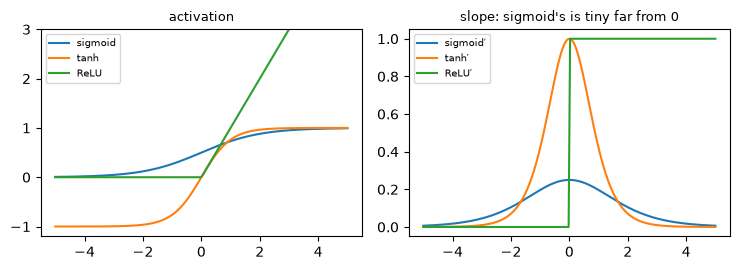

In [4]:
def activation_plots():
    x = np.linspace(-5, 5, 200)
    s = 1 / (1 + np.exp(-x))
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    left.plot(x, s, label="sigmoid")
    left.plot(x, np.tanh(x), label="tanh")
    left.plot(x, np.maximum(0, x), label="ReLU")
    left.set_ylim(-1.2, 3)
    left.legend(fontsize=7)
    left.set_title("activation", fontsize=9)
    right.plot(x, s * (1 - s), label="sigmoid′")
    right.plot(x, 1 - np.tanh(x) ** 2, label="tanh′")
    right.plot(x, (x > 0).astype(float), label="ReLU′")
    right.legend(fontsize=7)
    right.set_title("slope: sigmoid's is tiny far from 0", fontsize=9)
    fig.tight_layout()


activation_plots()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q10](#q10), [Q11](#q11), [Q12](#q12), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 4: Backpropagation

*Level: Core*

Training needs the gradient of the loss with respect to **every** weight. **Backpropagation** gets them all at once using the chain rule:




1. **Forward**: compute and remember every layer's values.
2. **Loss**: ½·mean(ŷ − y)² for regression, cross-entropy for classification.
3. **Backward**: start from the error at the output and multiply by each layer's local derivative, moving back towards the input.
4. **Update**: w ← w − learning\_rate × gradient.



The total cost is about the same as one forward pass, which is why networks with billions of weights can be trained at all. Check hand-written gradients against a numerical estimate.



**Vanishing gradients**: multiplying many slopes below 1 shrinks the signal. With sigmoid, ten layers multiply by at most 0.25¹⁰ ≈ 0.000001. ReLU, careful initialisation and skip connections fix this.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
import math


def backprop_by_hand():
    w1, b1, w2, b2 = 0.5, 0.1, -0.6, 0.2
    x, y = 1.0, 1.0
    z = w1 * x + b1
    h = math.tanh(z)
    pred = w2 * h + b2
    loss = 0.5 * (pred - y) ** 2
    dL_dpred = pred - y
    dpred_dh = w2
    dh_dz = 1 - h ** 2
    dz_dw1 = x
    dL_dw1 = dL_dpred * dpred_dh * dh_dz * dz_dw1
    dL_dw2 = dL_dpred * h
    new_w1 = w1 - 0.1 * dL_dw1
    new_w2 = w2 - 0.1 * dL_dw2
    new_pred = new_w2 * math.tanh(new_w1 * x + b1) + b2
    new_loss = 0.5 * (new_pred - y) ** 2


backprop_by_hand()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q16](#q16), [Q17](#q17), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: Backpropagation with real numbers

*Level: Core*

One input, one tanh neuron, one output: w₁ = 0.5, b = 0.1, w₂ = −0.6, b₂ = 0.2. The example is x = 1, y = 1.



#### Forward: store every value



| Quantity | Calculation | Value |
| --- | --- | --- |
| z | 0.5 × 1 + 0.1 | 0.600 |
| h | tanh(0.6) | 0.537 |
| ŷ | −0.6 × 0.537 + 0.2 | −0.122 |
| Loss | ½(−0.122 − 1)² | 0.630 |



#### Backward: multiply local slopes



| Slope | Formula | Value |
| --- | --- | --- |
| dL/dŷ | ŷ − y | −1.122 |
| dŷ/dh | w₂ | −0.6 |
| dh/dz | 1 − h² | 0.712 |
| dz/dw₁ | x | 1 |



- dL/dw₁ = (−1.122)(−0.6)(0.712)(1) = **0.479**
- dL/dw₂ = (ŷ − y) × h = (−1.122)(0.537) = **−0.603**



#### Update with learning rate 0.1



w₁ = 0.5 − 0.1 × 0.479 = 0.452, and w₂ = −0.6 + 0.0603 = −0.540. The new prediction is −0.071, and the loss falls from 0.630 to **0.574**.



**Why it's efficient:** dL/dŷ and dŷ/dh are shared by everything earlier in the network. Computing backwards reuses them instead of repeating that work for each weight.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
import math


def backprop_numbers():
    w1, b, w2, b2 = 0.5, 0.1, -0.6, 0.2
    x, y = 1.0, 1.0
    z = w1 * x + b
    h = math.tanh(z)
    pred = w2 * h + b2
    loss = 0.5 * (pred - y) ** 2
    dL_dpred = pred - y
    dh_dz = 1 - h ** 2
    dL_dw1 = dL_dpred * w2 * dh_dz * x
    dL_dw2 = dL_dpred * h
    new_w1 = w1 - 0.1 * dL_dw1
    new_w2 = w2 - 0.1 * dL_dw2
    new_pred = new_w2 * math.tanh(new_w1 * x + b) + b2
    new_loss = 0.5 * (new_pred - y) ** 2


backprop_numbers()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 6: How hidden neurons build curves

*Level: Core*

A single tanh or ReLU neuron makes one bend. Add more neurons and the network adds more bends. The demo fits a wavy curve with 1, 3 and 20 hidden neurons.



- **1 neuron:** one bend; it underfits.
- **3 neurons:** follows the main shape.
- **20 neurons:** follows it closely.



#### Wider or deeper?



One hidden layer can in principle approximate any smooth function, if it's wide enough. In practice, **depth** is more efficient: layers reuse each other's features. In images, for example, edges combine into shapes and then objects.



#### How big should it be?



1. Start small: one or two hidden layers of 32–128 neurons for tables.
2. Check that it can overfit a tiny sample. If it can't, there's a bug or the learning rate is wrong.
3. Grow until validation stops improving, then regularise.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

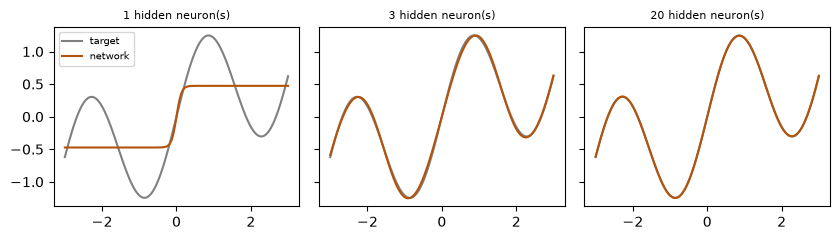

In [7]:
import warnings


def neurons_fit_curve():
    from sklearn.neural_network import MLPRegressor
    x = np.linspace(-3, 3, 120).reshape(-1, 1)
    y = np.sin(2 * x.ravel()) + 0.3 * x.ravel()
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.5), sharey=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for ax, size in zip(axes, [1, 3, 20]):
            net = MLPRegressor(hidden_layer_sizes=(size,), activation="tanh", solver="lbfgs", max_iter=3000, random_state=0).fit(x, y)
            ax.plot(x, y, color="gray", label="target")
            ax.plot(x, net.predict(x), color="#b45309", label="network")
            ax.set_title(f"{size} hidden neuron(s)", fontsize=8)
    axes[0].legend(fontsize=7)
    fig.tight_layout()


neurons_fit_curve()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q12](#q12), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 7: Momentum and Adam by hand

*Level: Core*

#### Momentum



Minimise f(w) = w² from w = 5, with learning rate 0.1 and μ = 0.9. The slope is 2w.



| Step | Plain gradient descent | With momentum |
| --- | --- | --- |
| 1 | 4.00 | v = −1, w = 4.00 |
| 2 | 3.20 | v = 0.9(−1) − 0.8 = −1.7, w = 2.30 |
| 3 | 2.56 | v = 0.9(−1.7) − 0.46 = −1.99, w = 0.31 |
| 4 | 2.05 | v = 0.9(−1.99) − 0.062 = −1.853, w = −1.54 |



Momentum moves much faster, then overshoots, like a heavy ball. It helps in narrow valleys where the zig-zags cancel out.



#### Adam: one step at a time



From w = 1 with learning rate 0.1:



| Step | Gradient | m̂ (average gradient) | v̂ (average squared) | New w |
| --- | --- | --- | --- | --- |
| 1 | 2.0 | 2.0 | 4.0 | 1 − 0.1 × 2 / 2 = 0.9 |
| 2 | 1.8 | 1.895 | 3.62 | 0.9 − 0.1 × 1.895 / 1.903 = 0.8 |



Dividing by √v̂ makes the step about the size of the learning rate, **whatever the gradient's scale**. That's why Adam needs less tuning. A sensible default learning rate is 0.001.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

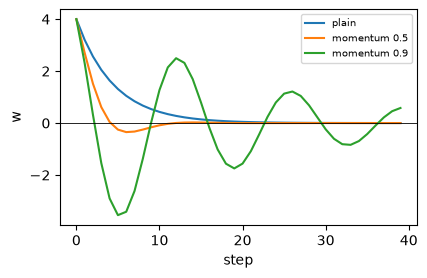

In [8]:
def momentum_vs_plain():
    def run(mu, steps=40, lr=0.1):
        w, v, path = 5.0, 0.0, []
        for _ in range(steps):
            v = mu * v - lr * 2 * w
            w = w + v
            path.append(w)
        return path

    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.plot(run(0.0), label="plain")
    ax.plot(run(0.5), label="momentum 0.5")
    ax.plot(run(0.9), label="momentum 0.9")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xlabel("step")
    ax.set_ylabel("w")
    ax.legend(fontsize=7)


momentum_vs_plain()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 8: Optimisers and practical training

*Level: Advanced*

Plain gradient descent is rarely used alone:




- **Mini-batches**: compute each step's gradient on a small group (32–512 rows), which is cheaper, and the noise can help.
- **Momentum**: keep a running velocity, which smooths zig-zags in narrow valleys.
- **Adam**: momentum plus a separate step size for each weight. The usual default.



**Initialisation**: start with small random weights (never all zeros, or neurons stay identical). Glorot and He ranges keep signal sizes steady across layers.



**Fighting overfitting**: **L2 / weight decay**, **dropout** (randomly silence neurons while training), **early stopping**, and more data. Always scale inputs.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

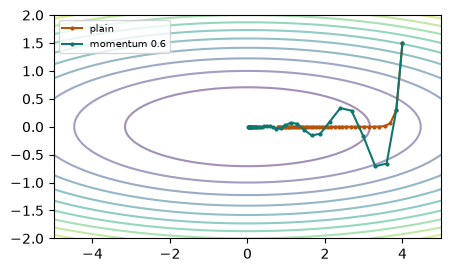

In [9]:
def optimiser_paths():
    def run(mu, steps=40, lr=0.02):
        w, v = np.array([4.0, 1.5]), np.zeros(2)
        path = [w]
        for _ in range(steps):
            g = np.array([2 * w[0], 40 * w[1]])
            v = mu * v - lr * g
            w = w + v
            path.append(w)
        return np.array(path)

    grid = np.linspace(-5, 5, 80)
    xx, yy = np.meshgrid(grid, grid / 2.5)
    fig, ax = plt.subplots(figsize=(5, 2.9))
    ax.contour(xx, yy, xx ** 2 + 20 * yy ** 2, levels=12, alpha=0.5)
    for mu, colour, name in [(0.0, "#b45309", "plain"), (0.6, "#0f766e", "momentum 0.6")]:
        path = run(mu)
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=2, color=colour, label=name)
    ax.legend(fontsize=7)


optimiser_paths()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q19](#q19), [Q8](#q8), [Q7](#q7), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 9: A real network in scikit-learn

*Level: Advanced*

`MLPClassifier` and `MLPRegressor` train a multi-layer perceptron in a few lines. Watch `loss_curve_`: a smooth fall is healthy, spikes mean the learning rate is too high, and a flat line means it's too low or the inputs aren't scaled.



A hidden layer lets the network bend its boundary. With enough neurons it can approximate any reasonable function (the **universal approximation theorem**), though that says nothing about how easy it is to train or whether it generalises.



**Where next:** for tables, gradient boosting usually wins. For images (CNNs), sequences and language (transformers), you need deep learning frameworks such as PyTorch. Their building blocks are exactly what you've built here.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

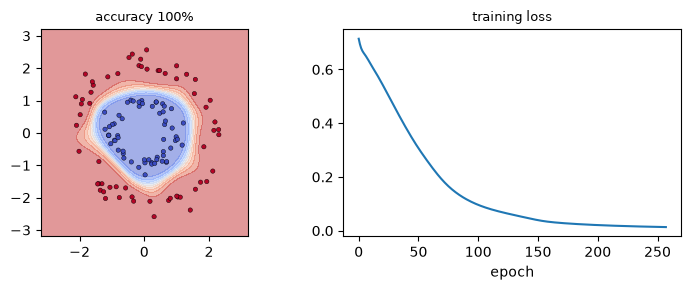

In [10]:
import warnings
from sklearn.neural_network import MLPClassifier
rng = np.random.default_rng(1)
angle = rng.uniform(0, 2 * np.pi, 120)
radius = np.r_[rng.normal(1, 0.15, 60), rng.normal(2.2, 0.2, 60)]
RINGS = np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])
RING_LABELS = np.r_[np.zeros(60, dtype=int), np.ones(60, dtype=int)]


def rings_boundary():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPClassifier(hidden_layer_sizes=(12,), activation="tanh", solver="adam", learning_rate_init=0.02,
                            max_iter=300, random_state=0).fit(RINGS, RING_LABELS)
    grid = np.linspace(-3.2, 3.2, 120)
    xx, yy = np.meshgrid(grid, grid)
    prob = net.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1].reshape(xx.shape)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 3))
    left.contourf(xx, yy, prob, levels=10, cmap="coolwarm", alpha=0.5)
    left.scatter(RINGS[:, 0], RINGS[:, 1], c=RING_LABELS, cmap="coolwarm", s=10, edgecolor="black", linewidth=0.3)
    left.set_aspect("equal")
    left.set_title(f"accuracy {net.score(RINGS, RING_LABELS):.0%}", fontsize=9)
    right.plot(net.loss_curve_)
    right.set_title("training loss", fontsize=9)
    right.set_xlabel("epoch")
    fig.tight_layout()


rings_boundary()

**✏️ Your turn:** you now have what you need for [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 10: Vanishing gradients

*Level: Advanced*

Backprop multiplies a slope per layer. Sigmoid's slope is at most 0.25, so the signal shrinks quickly:



| Layers | 2 | 5 | 10 |
| --- | --- | --- | --- |
| Largest possible factor (0.25ⁿ) | 0.0625 | 0.00098 | 0.00000095 |



Early layers then learn almost nothing. The demo pushes a real signal through 10 layers and shows the gradient at each one.



#### The fixes



| Fix | How it helps |
| --- | --- |
| ReLU | slope 1 for active neurons |
| Good initialisation (He, Glorot) | keeps signals a steady size |
| Normalisation layers | keep each layer's inputs in a healthy range |
| Skip connections (ResNet, transformers) | give gradients a direct path back |



**Exploding gradients** are the opposite problem: slopes above 1 multiply until the loss becomes NaN. Use gradient clipping and a lower learning rate.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

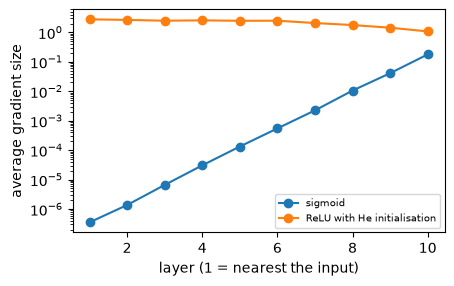

In [11]:
import math


def gradient_by_layer():
    r = np.random.default_rng(0)
    layers, width = 10, 64

    def run(activation, slope, weight_std):
        x = r.normal(size=(128, width))
        weights = [r.normal(0, weight_std, (width, width)) for _ in range(layers)]
        cache = []
        for W in weights:
            z = x @ W
            cache.append((W, slope(z)))
            x = activation(z)
        grad = np.ones_like(x)
        sizes = []
        for W, s in reversed(cache):
            grad = (grad * s) @ W.T
            sizes.append(np.abs(grad).mean())
        return sizes[::-1]

    sigmoid = run(lambda z: 1 / (1 + np.exp(-z)), lambda z: np.exp(-z) / (1 + np.exp(-z)) ** 2, 1 / math.sqrt(width))
    relu = run(lambda z: np.maximum(0, z), lambda z: (z > 0).astype(float), math.sqrt(2 / width))
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.semilogy(range(1, layers + 1), sigmoid, "o-", label="sigmoid")
    ax.semilogy(range(1, layers + 1), relu, "o-", label="ReLU with He initialisation")
    ax.set_xlabel("layer (1 = nearest the input)")
    ax.set_ylabel("average gradient size")
    ax.legend(fontsize=7)


gradient_by_layer()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 11: Debugging a network that won't learn

*Level: Advanced*

| Loss curve | Likely cause | Fix |
| --- | --- | --- |
| Explodes or becomes NaN | learning rate too high | divide it by 10; check for bad inputs |
| Flat from the start | rate too low, unscaled inputs, or a bug | scale inputs; try overfitting a tiny batch |
| Falls, then jumps around | rate too high near the minimum | use a schedule to lower it |
| Train falls, validation rises | overfitting | weight decay, dropout, early stopping, more data |



#### The checklist, in order



1. Is the starting loss about what you'd expect? For k equal classes it's near ln k.
2. Can it overfit 10 rows? If not, there's a bug.
3. Are inputs scaled, and are labels aligned with rows?
4. Find a learning rate: try 0.1, 0.01, 0.001.
5. Only then add regularisation and size.



**Common bugs:** softmax applied before a loss that expects raw scores, forgetting to clear gradients in PyTorch, leaving dropout on during evaluation.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

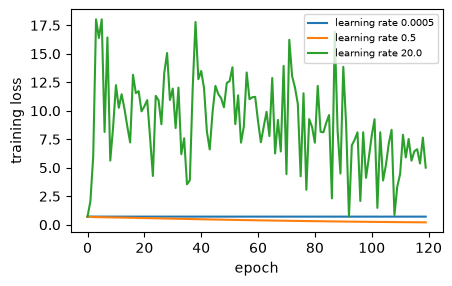

In [12]:
import warnings
from sklearn.neural_network import MLPClassifier
rng = np.random.default_rng(1)
angle = rng.uniform(0, 2 * np.pi, 120)
radius = np.r_[rng.normal(1, 0.15, 60), rng.normal(2.2, 0.2, 60)]
RINGS = np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])
RING_LABELS = np.r_[np.zeros(60, dtype=int), np.ones(60, dtype=int)]


def learning_rate_curves():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fig, ax = plt.subplots(figsize=(4.8, 2.9))
        for lr in [0.0005, 0.5, 20.0]:
            net = MLPClassifier(hidden_layer_sizes=(12,), activation="tanh", solver="sgd", momentum=0.0, learning_rate_init=lr,
                                max_iter=120, tol=0, n_iter_no_change=1000, random_state=0).fit(RINGS, RING_LABELS)
            ax.plot(net.loss_curve_, label=f"learning rate {lr}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("training loss")
    ax.legend(fontsize=7)


learning_rate_curves()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q5](#q5), [Q6](#q6), [Q14](#q14), [Q15](#q15), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 12: A whole network from scratch

*Level: Advanced*

Everything comes together here, in about 20 lines of NumPy and no framework. The demo trains on the rings dataset:



1. **Initialise** with small random weights.
2. **Forward:** h = tanh(X·W₁ + b₁), then p = σ(h·W₂ + b₂).
3. **Loss:** binary cross-entropy.
4. **Backward:** the output's error p − y flows back through W₂, then through the slope of tanh, into W₁.
5. **Update:** every weight moves against its gradient.
6. Repeat, recording the loss.



Compare the code with sklearn's `MLPClassifier` in the earlier lesson. PyTorch adds automatic gradients, GPU speed and ready-made layers, but this loop of forward, loss, backward and update is what every deep learning model does, including the largest language models.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

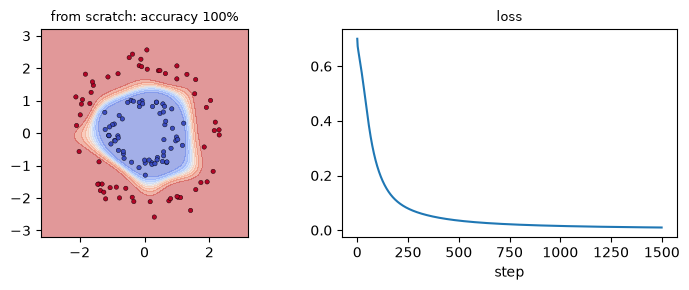

In [13]:
rng = np.random.default_rng(1)
angle = rng.uniform(0, 2 * np.pi, 120)
radius = np.r_[rng.normal(1, 0.15, 60), rng.normal(2.2, 0.2, 60)]
RINGS = np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])
RING_LABELS = np.r_[np.zeros(60, dtype=int), np.ones(60, dtype=int)]


def network_from_scratch():
    r = np.random.RandomState(0)
    X, y = RINGS, RING_LABELS.astype(float)
    W1, b1 = r.normal(0, 0.5, (2, 10)), np.zeros(10)
    W2, b2 = r.normal(0, 0.5, 10), 0.0
    losses = []
    for step in range(1500):
        h = np.tanh(X @ W1 + b1)
        p = 1 / (1 + np.exp(-(h @ W2 + b2)))
        losses.append(-(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)).mean())
        error = p - y
        slope_h = error[:, None] * W2 * (1 - h ** 2)
        W2 -= 0.5 * h.T @ error / len(y)
        b2 -= 0.5 * error.mean()
        W1 -= 0.5 * X.T @ slope_h / len(y)
        b1 -= 0.5 * slope_h.mean(axis=0)
    accuracy = ((p >= 0.5) == y).mean()
    grid = np.linspace(-3.2, 3.2, 100)
    xx, yy = np.meshgrid(grid, grid)
    points = np.column_stack([xx.ravel(), yy.ravel()])
    surface = 1 / (1 + np.exp(-(np.tanh(points @ W1 + b1) @ W2 + b2)))
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 3))
    left.contourf(xx, yy, surface.reshape(xx.shape), levels=10, cmap="coolwarm", alpha=0.5)
    left.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10, edgecolor="black", linewidth=0.3)
    left.set_aspect("equal")
    left.set_title(f"from scratch: accuracy {accuracy:.0%}", fontsize=9)
    right.plot(losses)
    right.set_xlabel("step")
    right.set_title("loss", fontsize=9)
    fig.tight_layout()


network_from_scratch()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q17](#q17). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [14]:
import math

import warnings

from sklearn.neural_network import MLPRegressor, MLPClassifier

from sklearn.metrics import log_loss, mean_squared_error


<a id="q1"></a>
### Q1. Logic Gates With One Neuron

🟢 Warm-up · *Weights decide the rule*

A neuron outputs 1 when w·x + b ≥ 0, else 0. Return its output for every row.

**Examples**

- `X = [[0, 0], [0, 1], [1, 0], [1, 1]], w = [1, 1], b = -1.5` → `[0, 0, 0, 1]`
- `X = [[0, 0], [0, 1], [1, 0], [1, 1]], w = [1, 1], b = -0.5` → `[0, 1, 1, 1]`
- `X = [[0], [1]], w = [-1], b = 0.5` → `[1, 0]`

In [ ]:
def neuron(X, w, b):
    """
    A neuron outputs 1 when w·x + b ≥ 0, else 0. Return its output for every
    row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(neuron, [
    (([[0, 0], [0, 1], [1, 0], [1, 1]], [1, 1], -1.5), [0, 0, 0, 1]),
    (([[0, 0], [0, 1], [1, 0], [1, 1]], [1, 1], -0.5), [0, 1, 1, 1]),
    (([[0], [1]], [-1], 0.5), [1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score each row in a loop, compare with 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `(X @ w + b >= 0).astype(int)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Score each row in a loop, compare with 0.

```python
def neuron(X, w, b):
    out = []
    for row in X:
        z = b + sum(wi * xi for wi, xi in zip(w, row))
        out.append(1 if z >= 0 else 0)
    return out
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Vectorised: `(X @ w + b >= 0).astype(int)`.

```python
def neuron(X, w, b):
    return (np.array(X) @ np.array(w) + b >= 0).astype(int)
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score each row in a loop, compare with 0. That costs O(n·d) time and O(n) space."

"I can do better: Vectorised: `(X @ w + b >= 0).astype(int)`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/logic-gates-with-one-neuron)

<a id="q2"></a>
### Q2. Activation Functions

🟢 Warm-up · *Sigmoid, tanh, ReLU*

Return (sigmoid(x), tanh(x), ReLU(x)) for each x, rounded to 4 decimals.

**Examples**

- `xs = [-2, 0, 1.5]` → `[(0.1192, -0.964, 0.0), (0.5, 0.0, 0.0), (0.8176, 0.9051, 1.5)]`

In [ ]:
def activations(xs):
    """
    Return (sigmoid(x), tanh(x), ReLU(x)) for each x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(activations, [
    (([-2, 0, 1.5],), [(0.1192, -0.964, 0.0), (0.5, 0.0, 0.0), (0.8176, 0.9051, 1.5)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Formulas with `math.exp` in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy on the whole array.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Formulas with `math.exp` in a loop.

```python
def activations(xs):
    out = []
    for x in xs:
        s = 1 / (1 + math.exp(-x))
        t = (math.exp(x) - math.exp(-x)) / (math.exp(x) + math.exp(-x))
        out.append((round(s, 4), round(t, 4) + 0.0, round(max(0.0, x), 4)))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** NumPy on the whole array.

```python
def activations(xs):
    x = np.array(xs, dtype=float)
    table = np.column_stack([1 / (1 + np.exp(-x)), np.tanh(x), np.maximum(0, x)]).round(4) + 0.0
    return [tuple(row) for row in table.tolist()]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Formulas with `math.exp` in a loop. That costs O(n) time and O(n) space."

"I can do better: NumPy on the whole array. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/activation-functions)

<a id="q3"></a>
### Q3. Count the Parameters

🟢 Warm-up · *Weights + biases*

A fully connected network has the given layer sizes, e.g. [3, 4, 2]. Return its number of parameters.

**Examples**

- `sizes = [3, 4, 2]` → `26`
- `sizes = [2, 5, 5, 1]` → `51`

In [ ]:
def count_params(sizes):
    """
    A fully connected network has the given layer sizes, e.g. [3, 4, 2]. Return
    its number of parameters.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(count_params, [
    (([3, 4, 2],), 26),
    (([2, 5, 5, 1],), 51),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each layer has inputs × outputs weights plus one bias per output.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build an `MLPRegressor` with those sizes and add up the sizes of `coefs_` and `intercepts_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Each layer has inputs × outputs weights plus one bias per output.

```python
def count_params(sizes):
    total = 0
    for a, b in zip(sizes, sizes[1:]):
        total += a * b + b
    return total
```

**Cost:** O(layers) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Build an `MLPRegressor` with those sizes and add up the sizes of `coefs_` and `intercepts_`.

```python
def count_params(sizes):
    d, hidden, k = sizes[0], tuple(sizes[1:-1]), sizes[-1]
    y = np.zeros(2) if k == 1 else np.zeros((2, k))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPRegressor(hidden_layer_sizes=hidden, max_iter=1, random_state=0).fit(np.zeros((2, d)), y)
    return int(sum(c.size for c in net.coefs_) + sum(b.size for b in net.intercepts_))
```

**Cost:** O(params) time, O(params) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each layer has inputs × outputs weights plus one bias per output. That costs O(layers) time and O(1) space."

"I can do better: Build an `MLPRegressor` with those sizes and add up the sizes of `coefs_` and `intercepts_`. That's O(params) time and O(params) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/count-the-parameters)

<a id="q4"></a>
### Q4. Classifier Output Layer

🟢 Warm-up · *Softmax, then pick the winner*

For each row of raw output scores return (probabilities rounded to 4 decimals, predicted class).

**Examples**

- `scores = [[2.0, 1.0, 0.1], [-1.0, 3.0, 0.0]]` → `[([0.659, 0.2424, 0.0986], 0), ([0.0171, 0.9362, 0.0466], 1)]`

In [ ]:
from scipy.special import softmax as scipy_softmax

def output_layer(scores):
    """
    For each row of raw output scores return (probabilities rounded to 4
    decimals, predicted class).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(output_layer, [
    (([[2.0, 1.0, 0.1], [-1.0, 3.0, 0.0]],), [([0.659, 0.2424, 0.0986], 0), ([0.0171, 0.9362, 0.0466], 1)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Exponentiate after subtracting the max, divide by the sum, find the largest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`scipy.special.softmax(z, axis=1)` and `argmax`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Exponentiate after subtracting the max, divide by the sum, find the largest.

```python
def output_layer(scores):
    out = []
    for row in scores:
        top = max(row)
        e = [math.exp(v - top) for v in row]
        p = [round(v / sum(e), 4) for v in e]
        out.append((p, p.index(max(p))))
    return out
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `scipy.special.softmax(z, axis=1)` and `argmax`.

```python
def output_layer(scores):
    p = scipy_softmax(np.array(scores, dtype=float), axis=1)
    return [(row.round(4).tolist(), int(row.argmax())) for row in p]
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Exponentiate after subtracting the max, divide by the sum, find the largest. That costs O(n·k) time and O(k) space."

"I can do better: `scipy.special.softmax(z, axis=1)` and `argmax`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/classifier-output-layer)

<a id="q5"></a>
### Q5. Regression Loss

🟢 Warm-up · *½ · mean squared error*

Return ½·mean((ŷ − y)²), the loss sklearn's MLP minimises, rounded to 4 decimals. The ½ cancels when differentiating.

**Examples**

- `y = [1.0, 2.0, 3.0], pred = [1.5, 2.0, 2.0]` → `0.2083`

In [ ]:
def half_mse(y, pred):
    """
    Return ½·mean((ŷ − y)²), the loss sklearn's MLP minimises, rounded to 4
    decimals. The ½ cancels when differentiating.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(half_mse, [
    (([1.0, 2.0, 3.0], [1.5, 2.0, 2.0]), 0.2083),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop of squared differences.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`mean_squared_error(y, pred) / 2`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop of squared differences.

```python
def half_mse(y, pred):
    return round(sum((a - b) ** 2 for a, b in zip(y, pred)) / (2 * len(y)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `mean_squared_error(y, pred) / 2`.

```python
def half_mse(y, pred):
    return round(mean_squared_error(y, pred) / 2, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop of squared differences. That costs O(n) time and O(1) space."

"I can do better: `mean_squared_error(y, pred) / 2`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/regression-loss)

<a id="q6"></a>
### Q6. Cross-Entropy for a Batch

🟢 Warm-up · *The classifier's loss*

Rows of P hold class probabilities and y holds the true class. Return the mean of −ln P[true class], rounded to 4 decimals.

**Examples**

- `y = [0, 1], P = [[0.8, 0.2], [0.3, 0.7]]` → `0.2899`

In [ ]:
def batch_ce(y, P):
    """
    Rows of P hold class probabilities and y holds the true class. Return the
    mean of −ln P[true class], rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batch_ce, [
    (([0, 1], [[0.8, 0.2], [0.3, 0.7]]), 0.2899),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Look up the true class's probability in each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`log_loss(y, P)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Look up the true class's probability in each row.

```python
def batch_ce(y, P):
    return round(sum(-math.log(row[c]) for c, row in zip(y, P)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `log_loss(y, P)`.

```python
def batch_ce(y, P):
    return round(log_loss(y, P, labels=list(range(len(P[0])))), 4)
```

**Cost:** O(n·k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Look up the true class's probability in each row. That costs O(n) time and O(1) space."

"I can do better: `log_loss(y, P)`. That's O(n·k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/cross-entropy-for-a-batch)

<a id="q7"></a>
### Q7. Initialisation Range

🟢 Warm-up · *Glorot: keep signals a sensible size*

sklearn's MLP draws each layer's starting weights uniformly in ±√(6 / (fan\_in + fan\_out)). For the given layer sizes, return each layer's bound, rounded to 4 decimals.

**Examples**

- `sizes = [3, 4, 2]` → `[0.9258, 1.0]`
- `sizes = [5, 16, 1]` → `[0.5345, 0.5941]`

In [ ]:
def init_bounds(sizes):
    """
    sklearn's MLP draws each layer's starting weights uniformly in ±√(6 /
    (fan_in + fan_out)). For the given layer sizes, return each layer's bound,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(init_bounds, [
    (([3, 4, 2],), [0.9258, 1.0]),
    (([5, 16, 1],), [0.5345, 0.5941]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the formula to each neighbouring pair of sizes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build a real network, read each weight matrix's shape, and confirm its largest weight really is inside the bound.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Apply the formula to each neighbouring pair of sizes.

```python
def init_bounds(sizes):
    out = []
    for fan_in, fan_out in zip(sizes, sizes[1:]):
        out.append(round(math.sqrt(6 / (fan_in + fan_out)), 4))
    return out
```

**Cost:** O(layers) time, O(layers) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Build a real network, read each weight matrix's shape, and confirm its largest weight really is inside the bound.

```python
def init_bounds(sizes):
    d, hidden, k = sizes[0], tuple(sizes[1:-1]), sizes[-1]
    y = np.zeros(2) if k == 1 else np.zeros((2, k))
    net = MLPRegressor(hidden_layer_sizes=hidden, solver="sgd", learning_rate_init=1e-12, momentum=0.0, random_state=0)
    net.partial_fit(np.zeros((2, d)), y)
    bounds = [math.sqrt(6 / sum(W.shape)) for W in net.coefs_]
    assert all(np.abs(W).max() <= b + 1e-6 for W, b in zip(net.coefs_, bounds))
    return [round(b, 4) for b in bounds]
```

**Cost:** O(params) time, O(params) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the formula to each neighbouring pair of sizes. That costs O(layers) time and O(layers) space."

"I can do better: Build a real network, read each weight matrix's shape, and confirm its largest weight really is inside the bound. That's O(params) time and O(params) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/initialisation-range)

<a id="q8"></a>
### Q8. Mini-Batches

🟢 Warm-up · *Slice the data*

Return (start, stop) for each mini-batch of up to size rows when walking through n rows in order.

**Examples**

- `n = 10, size = 4` → `[(0, 4), (4, 8), (8, 10)]`
- `n = 6, size = 2` → `[(0, 2), (2, 4), (4, 6)]`

In [ ]:
from sklearn.utils import gen_batches

def batches(n, size):
    """
    Return (start, stop) for each mini-batch of up to size rows when walking
    through n rows in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batches, [
    ((10, 4), [(0, 4), (4, 8), (8, 10)]),
    ((6, 2), [(0, 2), (2, 4), (4, 6)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop stepping by size.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.utils.gen_batches(n, size)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** A while loop stepping by size.

```python
def batches(n, size):
    out, start = [], 0
    while start < n:
        out.append((start, min(start + size, n)))
        start += size
    return out
```

**Cost:** O(n / size) time, O(n / size) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.utils.gen_batches(n, size)`.

```python
def batches(n, size):
    return [(s.start, s.stop) for s in gen_batches(n, size)]
```

**Cost:** O(n / size) time, O(n / size) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop stepping by size. That costs O(n / size) time and O(n / size) space."

"I can do better: `sklearn.utils.gen_batches(n, size)`. That's O(n / size) time and O(n / size) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/mini-batches)

<a id="q9"></a>
### Q9. XOR Needs a Hidden Layer

🟡 Interview standard · *Stacking neurons*

No single line separates XOR. Build it from gates: h₁ = OR, h₂ = NAND, output = AND(h₁, h₂). Return the output for every row.

**Examples**

- `X = [[0, 0], [0, 1], [1, 0], [1, 1]]` → `[0, 1, 1, 0]`

In [ ]:
def xor_net(X):
    """
    No single line separates XOR. Build it from gates: h₁ = OR, h₂ = NAND,
    output = AND(h₁, h₂). Return the output for every row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(xor_net, [
    (([[0, 0], [0, 1], [1, 0], [1, 1]],), [0, 1, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each gate as a separate neuron, row by row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two matrix layers: `H = (X @ W1 + b1 >= 0)`, then `(H @ W2 + b2 >= 0)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute each gate as a separate neuron, row by row.

```python
def xor_net(X):
    out = []
    for a, b in X:
        h1 = 1 if a + b - 0.5 >= 0 else 0
        h2 = 1 if -a - b + 1.5 >= 0 else 0
        out.append(1 if h1 + h2 - 1.5 >= 0 else 0)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Two matrix layers: `H = (X @ W1 + b1 >= 0)`, then `(H @ W2 + b2 >= 0)`.

```python
def xor_net(X):
    W1 = np.array([[1, 1], [-1, -1]])
    b1 = np.array([-0.5, 1.5])
    H = (np.array(X) @ W1.T + b1 >= 0).astype(int)
    return (H @ np.array([1, 1]) - 1.5 >= 0).astype(int)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each gate as a separate neuron, row by row. That costs O(n) time and O(n) space."

"I can do better: Two matrix layers: `H = (X @ W1 + b1 >= 0)`, then `(H @ W2 + b2 >= 0)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/xor-needs-a-hidden-layer)

<a id="q10"></a>
### Q10. Slopes of the Activations

🟡 Interview standard · *Why sigmoids make gradients vanish*

Return (σ′(x), tanh′(x), ReLU′(x)) for each x ≠ 0, rounded to 4 decimals.

**Examples**

- `xs = [-3, 0.5, 2]` → `[(0.0452, 0.0099, 0.0), (0.235, 0.7864, 1.0), (0.105, 0.0707, 1.0)]`

In [ ]:
def slopes(xs):
    """
    Return (σ′(x), tanh′(x), ReLU′(x)) for each x ≠ 0, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(slopes, [
    (([-3, 0.5, 2],), [(0.0452, 0.0099, 0.0), (0.235, 0.7864, 1.0), (0.105, 0.0707, 1.0)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical central difference of each function.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Exact: σ(1 − σ), 1 − tanh², and 1 for x &gt; 0 else 0.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Numerical central difference of each function.

```python
def slopes(xs):
    fns = [lambda z: 1 / (1 + math.exp(-z)), math.tanh, lambda z: max(0.0, z)]
    h = 1e-5
    return [tuple(round((f(x + h) - f(x - h)) / (2 * h), 4) for f in fns) for x in xs]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Exact: σ(1 − σ), 1 − tanh², and 1 for x &gt; 0 else 0.

```python
def slopes(xs):
    x = np.array(xs, dtype=float)
    s = 1 / (1 + np.exp(-x))
    table = np.column_stack([s * (1 - s), 1 - np.tanh(x) ** 2, (x > 0).astype(float)]).round(4)
    return [tuple(row) for row in table.tolist()]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical central difference of each function. That costs O(n) time and O(n) space."

"I can do better: Exact: σ(1 − σ), 1 − tanh², and 1 for x &gt; 0 else 0. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/slopes-of-the-activations)

<a id="q11"></a>
### Q11. Forward Pass With ReLU

🟡 Interview standard · *Input → hidden → output*

Compute W2·ReLU(W1·x + b1) + b2 for each row of X (each row of W is one neuron). Round to 4 decimals.

**Examples**

- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]]` → `[-0.22, 0.02, 0.47, 0.08]`

In [ ]:
def forward_relu(W1, b1, W2, b2, X):
    """
    Compute W2·ReLU(W1·x + b1) + b2 for each row of X (each row of W is one
    neuron). Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(forward_relu, [
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]]), [-0.22, 0.02, 0.47, 0.08]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over rows and neurons, one layer at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Put our weights in an `MLPRegressor` and call `predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loops over rows and neurons, one layer at a time.

```python
def forward_relu(W1, b1, W2, b2, X):
    out = []
    for row in X:
        hidden = []
        for w, b in zip(W1, b1):
            hidden.append(max(0.0, b + sum(wi * xi for wi, xi in zip(w, row))))
        out.append(round(b2[0] + sum(wi * h for wi, h in zip(W2[0], hidden)), 4))
    return out
```

**Cost:** O(n·params) time, O(h) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Put our weights in an `MLPRegressor` and call `predict`.

```python
def mlp_with_weights(W1, b1, W2, b2, activation):
    """A fitted MLPRegressor whose weights are replaced by ours. W rows hold one neuron each; sklearn stores the transpose."""
    W1, W2 = np.array(W1, dtype=float), np.array(W2, dtype=float)
    d, h, k = W1.shape[1], W1.shape[0], W2.shape[0]
    y = np.zeros(2) if k == 1 else np.zeros((2, k))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPRegressor(hidden_layer_sizes=(h,), activation=activation, max_iter=1, random_state=0).fit(np.zeros((2, d)), y)
    net.coefs_ = [W1.T, W2.T]
    net.intercepts_ = [np.array(b1, dtype=float), np.array(b2, dtype=float)]
    return net


def forward_relu(W1, b1, W2, b2, X):
    return mlp_with_weights(W1, b1, W2, b2, "relu").predict(X).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over rows and neurons, one layer at a time. That costs O(n·params) time and O(h) space."

"I can do better: Put our weights in an `MLPRegressor` and call `predict`. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/forward-pass-with-relu)

<a id="q12"></a>
### Q12. Forward Pass With tanh

🟡 Interview standard · *Same network, different bend*

Compute W2·tanh(W1·x + b1) + b2 for each row of X. Round to 4 decimals.

**Examples**

- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]]` → `[-0.1392, -0.0047, 0.3803, 0.086]`

In [ ]:
def forward_tanh(W1, b1, W2, b2, X):
    """
    Compute W2·tanh(W1·x + b1) + b2 for each row of X. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(forward_tanh, [
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]]), [-0.1392, -0.0047, 0.3803, 0.086]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

NumPy matrix products, layer by layer.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`MLPRegressor(activation='tanh')` holding our weights.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** NumPy matrix products, layer by layer.

```python
def forward_tanh(W1, b1, W2, b2, X):
    hidden = np.tanh(np.array(X) @ np.array(W1).T + np.array(b1))
    return (hidden @ np.array(W2).T + np.array(b2)).ravel().round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `MLPRegressor(activation='tanh')` holding our weights.

```python
def mlp_with_weights(W1, b1, W2, b2, activation):
    """A fitted MLPRegressor whose weights are replaced by ours. W rows hold one neuron each; sklearn stores the transpose."""
    W1, W2 = np.array(W1, dtype=float), np.array(W2, dtype=float)
    d, h, k = W1.shape[1], W1.shape[0], W2.shape[0]
    y = np.zeros(2) if k == 1 else np.zeros((2, k))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPRegressor(hidden_layer_sizes=(h,), activation=activation, max_iter=1, random_state=0).fit(np.zeros((2, d)), y)
    net.coefs_ = [W1.T, W2.T]
    net.intercepts_ = [np.array(b1, dtype=float), np.array(b2, dtype=float)]
    return net


def forward_tanh(W1, b1, W2, b2, X):
    return mlp_with_weights(W1, b1, W2, b2, "tanh").predict(X).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: NumPy matrix products, layer by layer. That costs O(n·params) time and O(n·h) space."

"I can do better: `MLPRegressor(activation='tanh')` holding our weights. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/forward-pass-with-tanh)

<a id="q13"></a>
### Q13. Momentum

🟡 Interview standard · *Build up speed*

Minimise f(w) = w² with v ← μ·v − lr·f′(w), w ← w + v, starting at v = 0. Return w after each step, rounded to 4 decimals.

**Examples**

- `w = 5.0, lr = 0.1, mu = 0.9, steps = 4` → `[4.0, 2.3, 0.31, -1.543]`
- `w = 5.0, lr = 0.1, mu = 0.0, steps = 3` → `[4.0, 3.2, 2.56]`

In [ ]:
def momentum(w, lr, mu, steps):
    """
    Minimise f(w) = w² with v ← μ·v − lr·f′(w), w ← w + v, starting at v = 0.
    Return w after each step, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(momentum, [
    ((5.0, 0.1, 0.9, 4), [4.0, 2.3, 0.31, -1.543]),
    ((5.0, 0.1, 0.0, 3), [4.0, 3.2, 2.56]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Plain Python loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Treat (w, v) as a vector: each step multiplies it by the same 2 × 2 matrix.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Plain Python loop.

```python
def momentum(w, lr, mu, steps):
    v = 0.0
    out = []
    for _ in range(steps):
        v = mu * v - lr * 2 * w
        w = w + v
        out.append(round(w, 4))
    return out
```

**Cost:** O(steps) time, O(steps) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Treat (w, v) as a vector: each step multiplies it by the same 2 × 2 matrix.

```python
def momentum(w, lr, mu, steps):
    A = np.array([[1 - 2 * lr, mu], [-2 * lr, mu]])
    state = np.array([w, 0.0])
    out = []
    for _ in range(steps):
        state = A @ state
        out.append(round(state[0], 4))
    return out
```

**Cost:** O(steps) time, O(steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Plain Python loop. That costs O(steps) time and O(steps) space."

"I can do better: Treat (w, v) as a vector: each step multiplies it by the same 2 × 2 matrix. That's O(steps) time and O(steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/momentum)

<a id="q14"></a>
### Q14. L2 Regularisation in a Network

🟡 Interview standard · *Weight decay*

Return (loss + (α/2n)·Σw², the same penalty sklearn's MLP adds) for the given data loss, weight arrays, α and batch size n, rounded to 4 decimals.

**Examples**

- `loss = 0.5, weights = [[[1, 2], [3, 4]], [[-1, 0.5]]], alpha = 0.1, n = 10` → `0.6562`

In [ ]:
def l2_loss(loss, weights, alpha, n):
    """
    Return (loss + (α/2n)·Σw², the same penalty sklearn's MLP adds) for the
    given data loss, weight arrays, α and batch size n, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(l2_loss, [
    ((0.5, [[[1, 2], [3, 4]], [[-1, 0.5]]], 0.1, 10), 0.6562),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops to add up every squared weight.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sum(np.square(W).sum() for W in weights)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Nested loops to add up every squared weight.

```python
def l2_loss(loss, weights, alpha, n):
    total = 0.0
    for W in weights:
        for row in W:
            for v in row:
                total += v * v
    return round(loss + alpha * total / (2 * n), 4)
```

**Cost:** O(params) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sum(np.square(W).sum() for W in weights)`.

```python
def l2_loss(loss, weights, alpha, n):
    total = sum(np.square(np.array(W, dtype=float)).sum() for W in weights)
    return round(loss + alpha * total / (2 * n), 4)
```

**Cost:** O(params) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops to add up every squared weight. That costs O(params) time and O(1) space."

"I can do better: `sum(np.square(W).sum() for W in weights)`. That's O(params) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/l2-regularisation-in-a-network)

<a id="q15"></a>
### Q15. Dropout

🟡 Interview standard · *Randomly silence neurons*

Keep each activation with probability keep, using np.random.RandomState(seed).rand(n) &lt; keep; scale the kept ones by 1/keep so the expected value is unchanged. Round to 4 decimals.

**Examples**

- `a = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0], keep = 0.5, seed = 0` → `[0.0, 0.0, 0.0, 0.0, 10.0, 0.0]`

In [ ]:
def dropout(a, keep, seed):
    """
    Keep each activation with probability keep, using
    np.random.RandomState(seed).rand(n) < keep; scale the kept ones by 1/keep so
    the expected value is unchanged. Round to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dropout, [
    (([1.0, 2.0, 3.0, 4.0, 5.0, 6.0], 0.5, 0), [0.0, 0.0, 0.0, 0.0, 10.0, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Draw one random number per activation in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A boolean mask multiplied in one line.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Draw one random number per activation in a loop.

```python
def dropout(a, keep, seed):
    rng = np.random.RandomState(seed)
    out = []
    for v in a:
        out.append(round(v / keep, 4) if rng.rand() < keep else 0.0)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A boolean mask multiplied in one line.

```python
def dropout(a, keep, seed):
    mask = np.random.RandomState(seed).rand(len(a)) < keep
    return (np.array(a) * mask / keep).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Draw one random number per activation in a loop. That costs O(n) time and O(n) space."

"I can do better: A boolean mask multiplied in one line. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/dropout)

<a id="q16"></a>
### Q16. Backpropagation Gradients

🔴 Stretch · *The chain rule, layer by layer*

For a tanh hidden layer and one linear output with loss ½·mean((ŷ − y)²), return the gradient with respect to W2's weights, rounded to 4 decimals.

**Examples**

- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], y = [1.0, 0.0, 1.0, 0.5]` → `[-0.2194, -0.2442]`

In [ ]:
def backprop_w2(W1, b1, W2, b2, X, y):
    """
    For a tanh hidden layer and one linear output with loss ½·mean((ŷ − y)²),
    return the gradient with respect to W2's weights, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backprop_w2, [
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], [1.0, 0.0, 1.0, 0.5]), [-0.2194, -0.2442]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nudge each weight a little and watch the loss (numerical gradient).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Backprop: the error times each hidden activation, averaged over rows.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Nudge each weight a little and watch the loss (numerical gradient).

```python
def backprop_w2(W1, b1, W2, b2, X, y):
    def loss(w2):
        total = 0
        for row, target in zip(X, y):
            hidden = [math.tanh(b + sum(a * c for a, c in zip(w, row))) for w, b in zip(W1, b1)]
            pred = b2[0] + sum(a * c for a, c in zip(w2, hidden))
            total += (pred - target) ** 2
        return total / (2 * len(X))

    h = 1e-6
    grads = []
    for j in range(len(W2[0])):
        up, down = list(W2[0]), list(W2[0])
        up[j] += h
        down[j] -= h
        grads.append(round((loss(up) - loss(down)) / (2 * h), 4))
    return grads
```

**Cost:** O(params·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Backprop: the error times each hidden activation, averaged over rows.

```python
def backprop_w2(W1, b1, W2, b2, X, y):
    hidden = np.tanh(np.array(X) @ np.array(W1).T + np.array(b1))
    err = (hidden @ np.array(W2).T + np.array(b2)).ravel() - np.array(y)
    return (hidden.T @ err / len(X)).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nudge each weight a little and watch the loss (numerical gradient). That costs O(params·n) time and O(1) space."

"I can do better: Backprop: the error times each hidden activation, averaged over rows. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/backpropagation-gradients)

<a id="q17"></a>
### Q17. One Training Step

🔴 Stretch · *Backprop + gradient descent*

Take one full-batch gradient step with learning rate lr. Return the network's predictions on X afterwards, rounded to 4 decimals.

**Examples**

- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], y = [1.0, 0.0, 1.0, 0.5], lr = 0.1` → `[-0.0077, 0.0908, 0.5114, 0.212]`
- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], y = [1.0, 0.0, 1.0, 0.5], lr = 0.5` → `[0.5443, 0.4689, 0.9879, 0.7052]`

In [ ]:
def one_step(W1, b1, W2, b2, X, y, lr):
    """
    Take one full-batch gradient step with learning rate lr. Return the
    network's predictions on X afterwards, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(one_step, [
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], [1.0, 0.0, 1.0, 0.5], 0.1), [-0.0077, 0.0908, 0.5114, 0.212]),
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], [1.0, 0.0, 1.0, 0.5], 0.5), [0.5443, 0.4689, 0.9879, 0.7052]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Forward pass, backward pass by hand for all four weight arrays, update, forward again.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`MLPRegressor(solver='sgd', momentum=0, alpha=0, batch_size=n)` starting from our weights; one `partial_fit`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Forward pass, backward pass by hand for all four weight arrays, update, forward again.

```python
def gd_step(W1, b1, W2, b2, X, y, lr):
    """One full-batch gradient step on ½·mean(ŷ − y)² for a tanh hidden layer and one linear output, by backprop."""
    n = len(X)
    h1 = X @ W1.T + b1
    a1 = np.tanh(h1)
    pred = (a1 @ W2.T + b2).ravel()
    err = pred - y
    dW2 = (a1.T @ err / n).reshape(1, -1)
    db2 = err.mean(keepdims=True)
    da = err[:, None] @ W2 * (1 - a1 ** 2)
    dW1 = (da.T @ X) / n
    db1 = da.mean(axis=0)
    return W1 - lr * dW1, b1 - lr * db1, W2 - lr * dW2, b2 - lr * db2


def one_step(W1, b1, W2, b2, X, y, lr):
    X, y = np.array(X), np.array(y)
    W1, b1, W2, b2 = gd_step(np.array(W1), np.array(b1), np.array(W2), np.array(b2), X, y, lr)
    return (np.tanh(X @ W1.T + b1) @ W2.T + b2).ravel().round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `MLPRegressor(solver='sgd', momentum=0, alpha=0, batch_size=n)` starting from our weights; one `partial_fit`.

```python
def sgd_net(W1, b1, W2, b2, X, y, lr):
    """sklearn MLP set up for plain full-batch gradient descent, starting from our weights."""
    net = MLPRegressor(hidden_layer_sizes=(len(W1),), activation="tanh", solver="sgd", learning_rate_init=lr,
                       momentum=0.0, alpha=0.0, batch_size=len(X), shuffle=False, random_state=0)
    net.partial_fit(X, y)  # builds the network and optimizer; overwrite in place so the optimizer keeps its references
    net.coefs_[0][:] = np.array(W1, dtype=float).T
    net.coefs_[1][:] = np.array(W2, dtype=float).T
    net.intercepts_[0][:] = b1
    net.intercepts_[1][:] = b2
    return net


def one_step(W1, b1, W2, b2, X, y, lr):
    net = sgd_net(W1, b1, W2, b2, X, y, lr)
    net.partial_fit(X, y)
    return net.predict(X).round(4)
```

**Cost:** O(n·params) time, O(n·h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Forward pass, backward pass by hand for all four weight arrays, update, forward again. That costs O(n·params) time and O(n·h) space."

"I can do better: `MLPRegressor(solver='sgd', momentum=0, alpha=0, batch_size=n)` starting from our weights; one `partial_fit`. That's O(n·params) time and O(n·h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/one-training-step)

<a id="q18"></a>
### Q18. A Short Training Loop

🔴 Stretch · *Watch the loss fall*

Run n full-batch steps (learning rate 0.1) and return ½·mean((ŷ − y)²) after each one, rounded to 4 decimals.

**Examples**

- `W1 = [[0.5, -0.2], [0.1, 0.4]], b1 = [0.1, -0.1], W2 = [[0.3, -0.6]], b2 = [0.2], X = [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], y = [1.0, 0.0, 1.0, 0.5], n = 5` → `[0.1682, 0.1276, 0.1017, 0.0851, 0.0745]`

In [ ]:
def training_loop(W1, b1, W2, b2, X, y, n):
    """
    Run n full-batch steps (learning rate 0.1) and return ½·mean((ŷ − y)²) after
    each one, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(training_loop, [
    (([[0.5, -0.2], [0.1, 0.4]], [0.1, -0.1], [[0.3, -0.6]], [0.2], [[1.0, 2.0], [0.0, 1.0], [2.0, 0.0], [1.0, 1.0]], [1.0, 0.0, 1.0, 0.5], 5), [0.1682, 0.1276, 0.1017, 0.0851, 0.0745]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeat the hand-written step and measure the loss.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Repeat `partial_fit` on the sklearn network and measure its predictions.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Repeat the hand-written step and measure the loss.

```python
def gd_step(W1, b1, W2, b2, X, y, lr):
    """One full-batch gradient step on ½·mean(ŷ − y)² for a tanh hidden layer and one linear output, by backprop."""
    n = len(X)
    h1 = X @ W1.T + b1
    a1 = np.tanh(h1)
    pred = (a1 @ W2.T + b2).ravel()
    err = pred - y
    dW2 = (a1.T @ err / n).reshape(1, -1)
    db2 = err.mean(keepdims=True)
    da = err[:, None] @ W2 * (1 - a1 ** 2)
    dW1 = (da.T @ X) / n
    db1 = da.mean(axis=0)
    return W1 - lr * dW1, b1 - lr * db1, W2 - lr * dW2, b2 - lr * db2


def training_loop(W1, b1, W2, b2, X, y, n):
    X, y = np.array(X), np.array(y)
    W1, b1, W2, b2 = np.array(W1), np.array(b1), np.array(W2), np.array(b2)
    losses = []
    for _ in range(n):
        W1, b1, W2, b2 = gd_step(W1, b1, W2, b2, X, y, 0.1)
        pred = (np.tanh(X @ W1.T + b1) @ W2.T + b2).ravel()
        losses.append(round(float(((pred - y) ** 2).mean() / 2), 4))
    return losses
```

**Cost:** O(steps·n·params) time, O(steps) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Repeat `partial_fit` on the sklearn network and measure its predictions.

```python
def sgd_net(W1, b1, W2, b2, X, y, lr):
    """sklearn MLP set up for plain full-batch gradient descent, starting from our weights."""
    net = MLPRegressor(hidden_layer_sizes=(len(W1),), activation="tanh", solver="sgd", learning_rate_init=lr,
                       momentum=0.0, alpha=0.0, batch_size=len(X), shuffle=False, random_state=0)
    net.partial_fit(X, y)  # builds the network and optimizer; overwrite in place so the optimizer keeps its references
    net.coefs_[0][:] = np.array(W1, dtype=float).T
    net.coefs_[1][:] = np.array(W2, dtype=float).T
    net.intercepts_[0][:] = b1
    net.intercepts_[1][:] = b2
    return net


def training_loop(W1, b1, W2, b2, X, y, n):
    net = sgd_net(W1, b1, W2, b2, X, y, 0.1)
    losses = []
    for _ in range(n):
        net.partial_fit(X, y)
        losses.append(round(mean_squared_error(y, net.predict(X)) / 2, 4))
    return losses
```

**Cost:** O(steps·n·params) time, O(steps) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeat the hand-written step and measure the loss. That costs O(steps·n·params) time and O(steps) space."

"I can do better: Repeat `partial_fit` on the sklearn network and measure its predictions. That's O(steps·n·params) time and O(steps) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/a-short-training-loop)

<a id="q19"></a>
### Q19. One Adam Update

🔴 Stretch · *Adaptive step sizes*

Apply t steps of Adam (β₁ = 0.9, β₂ = 0.999, ε = 1e-8, learning rate lr) to f(w) = Σwᵢ² from the given weights. Return the weights, rounded to 4 decimals.

**Examples**

- `w = [1.0, -2.0], lr = 0.1, t = 3` → `[0.7016, -1.7006]`

In [ ]:
def adam(w, lr, t):
    """
    Apply t steps of Adam (β₁ = 0.9, β₂ = 0.999, ε = 1e-8, learning rate lr) to
    f(w) = Σwᵢ² from the given weights. Return the weights, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(adam, [
    (([1.0, -2.0], 0.1, 3), [0.7016, -1.7006]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track m and v for each weight in lists, with bias correction.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same update as NumPy array operations — each weight gets its own step size.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Track m and v for each weight in lists, with bias correction.

```python
def adam(w, lr, t):
    w = list(w)
    m, v = [0.0] * len(w), [0.0] * len(w)
    for step in range(1, t + 1):
        for i in range(len(w)):
            g = 2 * w[i]
            m[i] = 0.9 * m[i] + 0.1 * g
            v[i] = 0.999 * v[i] + 0.001 * g * g
            mh = m[i] / (1 - 0.9 ** step)
            vh = v[i] / (1 - 0.999 ** step)
            w[i] -= lr * mh / (math.sqrt(vh) + 1e-8)
    return [round(x, 4) for x in w]
```

**Cost:** O(t·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** The same update as NumPy array operations — each weight gets its own step size.

```python
def adam(w, lr, t):
    w = np.array(w, dtype=float)
    m, v = np.zeros_like(w), np.zeros_like(w)
    for step in range(1, t + 1):
        g = 2 * w
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g ** 2
        w = w - lr * (m / (1 - 0.9 ** step)) / (np.sqrt(v / (1 - 0.999 ** step)) + 1e-8)
    return w.round(4)
```

**Cost:** O(t·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track m and v for each weight in lists, with bias correction. That costs O(t·d) time and O(d) space."

"I can do better: The same update as NumPy array operations — each weight gets its own step size. That's O(t·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/one-adam-update)

<a id="q20"></a>
### Q20. Learn XOR

🔴 Stretch · *Train a real network*

Train a one-hidden-layer network with 4 tanh neurons on XOR and return its predicted class for each row.

**Examples**

- `X = [[0, 0], [0, 1], [1, 0], [1, 1]], y = [0, 1, 1, 0]` → `[0, 1, 1, 0]`

In [ ]:
def learn_xor(X, y):
    """
    Train a one-hidden-layer network with 4 tanh neurons on XOR and return its
    predicted class for each row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(learn_xor, [
    (([[0, 0], [0, 1], [1, 0], [1, 1]], [0, 1, 1, 0]), [0, 1, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Full backprop in NumPy with a sigmoid output and log-loss: 5000 gradient steps from a seeded start.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`MLPClassifier(hidden_layer_sizes=(4,), activation='tanh', solver='lbfgs', random_state=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Full backprop in NumPy with a sigmoid output and log-loss: 5000 gradient steps from a seeded start.

```python
def learn_xor(X, y):
    X, y = np.array(X, dtype=float), np.array(y, dtype=float)
    rng = np.random.RandomState(0)
    W1, b1 = rng.uniform(-1, 1, (4, 2)), rng.uniform(-1, 1, 4)
    W2, b2 = rng.uniform(-1, 1, 4), 0.0
    for _ in range(5000):
        a = np.tanh(X @ W1.T + b1)
        p = 1 / (1 + np.exp(-(a @ W2 + b2)))
        err = p - y
        da = err[:, None] * W2 * (1 - a ** 2)
        W2 = W2 - 0.5 * a.T @ err / len(y)
        b2 = b2 - 0.5 * err.mean()
        W1 = W1 - 0.5 * da.T @ X / len(y)
        b1 = b1 - 0.5 * da.mean(axis=0)
    p = 1 / (1 + np.exp(-(np.tanh(X @ W1.T + b1) @ W2 + b2)))
    return (p >= 0.5).astype(int)
```

**Cost:** O(steps·n·params) time, O(params) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `MLPClassifier(hidden_layer_sizes=(4,), activation='tanh', solver='lbfgs', random_state=1)`.

```python
def learn_xor(X, y):
    net = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs", max_iter=2000, random_state=1)
    return net.fit(X, y).predict(X)
```

**Cost:** O(steps·n·params) time, O(params) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Full backprop in NumPy with a sigmoid output and log-loss: 5000 gradient steps from a seeded start. That costs O(steps·n·params) time and O(params) space."

"I can do better: `MLPClassifier(hidden_layer_sizes=(4,), activation='tanh', solver='lbfgs', random_state=1)`. That's O(steps·n·params) time and O(params) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/neural-networks/learn-xor)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why do neural networks need non-linear activations?</b></summary>

A composition of linear functions is still linear, so without them any depth of network could only model straight-line relationships.

</details>

<details>
<summary><b>2. What is backpropagation?</b></summary>

An efficient use of the chain rule that computes the gradient of the loss with respect to every weight by passing the error backwards through the network. The optimiser then uses those gradients to update the weights.

</details>

<details>
<summary><b>3. Why not initialise all weights to zero?</b></summary>

Neurons in a layer would compute the same output and receive the same gradient, so they'd stay identical forever. Random initialisation breaks that symmetry.

</details>

<details>
<summary><b>4. Why is ReLU preferred to sigmoid in hidden layers?</b></summary>

Its slope is 1 for positive inputs, so gradients don't shrink through many layers, and it is cheap to compute. Sigmoid's slope is at most 0.25 and nearly 0 for large inputs.

</details>

<details>
<summary><b>5. What does dropout do?</b></summary>

During training it randomly zeroes activations, which stops neurons relying on specific others and acts like averaging many smaller networks. It is switched off for prediction.

</details>

<details>
<summary><b>6. SGD vs Adam?</b></summary>

Adam adapts a step size per weight and usually trains quickly with little tuning. Well-tuned SGD with momentum can generalise as well or better on some problems, especially in vision.

</details>

<details>
<summary><b>7. How do you know a network is overfitting?</b></summary>

Training loss keeps falling while validation loss stops improving or rises. Add regularisation or data, shrink the network, or stop early.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: One neuron, then many
- [ ] I can explain: A forward pass by hand
- [ ] I can explain: Activations and the forward pass
- [ ] I can explain: Backpropagation
- [ ] I can explain: Backpropagation with real numbers
- [ ] I can explain: How hidden neurons build curves
- [ ] I can explain: Momentum and Adam by hand
- [ ] I can explain: Optimisers and practical training
- [ ] I can explain: A real network in scikit-learn
- [ ] I can explain: Vanishing gradients
- [ ] I can explain: Debugging a network that won't learn
- [ ] I can explain: A whole network from scratch

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Backpropagation Gradients
- [ ] [Q17](#q17) One Training Step
- [ ] [Q18](#q18) A Short Training Loop
- [ ] [Q19](#q19) One Adam Update
- [ ] [Q20](#q20) Learn XOR

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.